# Student Risk — Improved native/calibrated fusion

Notebook độc lập. Thay đổi chính là chuyên gia native CatBoost, tín hiệu sớm và calibration train-only. Giữ kết quả thực tế; không bảo đảm mẫu thắng/bằng/thua.

## Cell 1 — Cài thư viện

Có thêm CatBoost. Sau khi cài, Restart Kernel rồi chạy từ Cell2. Không cần dùng cell từ file cũ.

In [1]:
%pip install -q "numpy>=1.24" "pandas>=1.5" "scipy>=1.9" "scikit-learn>=1.2" "matplotlib>=3.6" "xgboost>=1.7" "catboost>=1.2.7" ucimlrepo kagglehub


Note: you may need to restart the kernel to use updated packages.


## Cell 2 — Cấu hình

Chỉnh UCI_FILE/OULAD khi cần. Giữ cả hai tập để chọn đồng thời bốn kết quả P/R. So sánh người dẫn đầu trong LR/DT/RF/XGB cho mỗi chỉ số, không dùng riêng XGBoost. Toàn bộ chênh lệch là ĐIỂM PHẦN TRĂM, không phải phần trăm tương đối. Không đổi tham số sau khi xem test.

In [2]:
import os
for key in ['OMP_NUM_THREADS','MKL_NUM_THREADS','OPENBLAS_NUM_THREADS']:os.environ[key]='1'
import json,hashlib,uuid,shutil,platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize,differential_evolution
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,average_precision_score,brier_score_loss,confusion_matrix,
 f1_score,fbeta_score,precision_score,recall_score,roc_auc_score,precision_recall_curve)
from sklearn.model_selection import StratifiedKFold,StratifiedGroupKFold,train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
SEED,OUTER_FOLDS,N_JOBS,BOOTSTRAPS=42,4,4,1000
TIMES=[7,14,21,28]
NAMES=['LR','DT','RF','XGB']
KEY=['code_module','code_presentation','id_student']
METRICS=['Precision','Recall','F1','F2']
PRECISION_TARGET={'UCI697':.70,'OULAD':.67}
UCI_FILE=Path('./uci_697/data.csv')
OULAD=Path('./oulad')

from catboost import CatBoostClassifier
from scipy.special import expit,logit
from sklearn.cluster import KMeans
from itertools import product
import math
DATASETS=["UCI697","OULAD"]
OUTPUT=Path("./improved_fusion_outputs")/("run_"+uuid.uuid4().hex[:8])
POOL_LIMIT=160
STATUS_EPS_PP = 1e-9
PRACTICAL_EQUIVALENCE_PP = 0.1
CALIBRATION_EPS = 1e-6
WEIGHT_EPS = 1e-12
PROTOCOL_FUSION='NATIVE_CALIBRATED_CONVEX_FUSION_V1'
EXPERT_NAMES=['LR','DT','RF','XGB','CBNative','CBSignals','CBState']
CAT_MAX_ITERATIONS=800
CAT_EARLY_STOP=80
CAT_MIN_ITERATIONS=50
LOSS_LIMIT_PP=1.0
CALIBRATION_MIN_GAIN=1e-4
print("Protocol:",PROTOCOL_FUSION)
print("Seven experts; global weights sum to one. Compare with ALL FOUR original baselines.")
print("Output:",OUTPUT.resolve())


Protocol: NATIVE_CALIBRATED_CONVEX_FUSION_V1
Seven experts; global weights sum to one. Compare with ALL FOUR original baselines.
Output: C:\Users\Tai\nckh_2026_2027\nckh\improved_fusion_outputs\run_48680d7b


## Cell 3 — Dữ liệu

Giữ nhãn và chia tập như bản trước: UCI Dropout=1, Enrolled/Graduate=0; chỉ học kỳ1. OULAD Fail/Withdrawn=1; còn đăng ký sau ngày28, dữ liệu7/14/21/28. Enrolled chưa chắc kết quả cuối; date_submitted chỉ đại diện thời điểm có điểm. OULAD chia theo id_student, không lẫn một sinh viên giữa các tập.

In [3]:
def load_uci(path):
    path = Path(path)
    if path.exists():
        df = pd.read_csv(path, sep=";")
    else:
        from ucimlrepo import fetch_ucirepo
        uci = fetch_ucirepo(id=697)
        df = pd.concat([uci.data.features, uci.data.targets], axis=1)
    df.columns = df.columns.str.strip()
    context = ["Course", "Application mode", "Application order", "Admission grade",
               "Previous qualification (grade)", "Age at enrollment", "Tuition fees up to date",
               "Debtor", "Scholarship holder"]
    academic = [f"Curricular units 1st sem ({s})" for s in
                ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]]
    cats = ["Course", "Application mode"]
    x = df[context + academic].copy()
    initial = [c for c in context if c not in cats]
    return dict(x=x, cats=cats, y=df.Target.eq("Dropout").to_numpy(dtype=int), groups=None,
                stages=[x[initial].copy(), x[initial+academic].copy()], times=[0, 1],
                ids=pd.DataFrame({"record_id": np.arange(len(df)), "recorded_status": df.Target}))

def load_oulad(path):
    path = Path(path)
    files = ["courses", "assessments", "studentAssessment", "studentInfo",
             "studentRegistration", "studentVle", "vle"]
    if not all((path/f"{f}.csv").exists() for f in files):
        import kagglehub
        downloaded = Path(kagglehub.dataset_download(
            "anlgrbz/student-demographics-online-education-dataoulad"))
        matches = [p.parent for p in downloaded.rglob("studentInfo.csv")
                   if all((p.parent/f"{f}.csv").exists() for f in files)]
        if not matches:
            raise FileNotFoundError("Không tìm thấy đủ 7 CSV OULAD")
        path = matches[0]
    info = pd.read_csv(path/"studentInfo.csv")
    reg = pd.read_csv(path/"studentRegistration.csv")
    base = info.merge(reg, on=KEY, validate="one_to_one").merge(
        pd.read_csv(path/"courses.csv"), on=KEY[:2], validate="many_to_one")
    cutoff = max(TIMES)
    eligible = (base.date_registration.fillna(0).le(cutoff)
                & (base.date_unregistration.isna() | base.date_unregistration.gt(cutoff)))
    base = base.loc[eligible].reset_index(drop=True)
    clicks = pd.read_csv(path/"studentVle.csv")
    clicks = clicks.loc[clicks.date.le(cutoff)].merge(
        pd.read_csv(path/"vle.csv", usecols=KEY[:2]+["id_site", "activity_type"]),
        on=KEY[:2]+["id_site"], validate="many_to_one")
    assessments = pd.read_csv(path/"studentAssessment.csv").merge(
        pd.read_csv(path/"assessments.csv"), on="id_assessment", validate="many_to_one")
    assessments = assessments.loc[assessments.assessment_type.ne("Exam") & assessments.is_banked.eq(0)]
    cats = ["gender", "highest_education", "age_band", "imd_band"]
    behavior = ["total_clicks", "clicks_last_7d", "active_days", "activity_diversity",
                "days_since_last_activity", "avg_assessment_score", "submissions_count",
                "completed_weight", "click_trend", "score_trend"]
    nums = ["num_of_prev_attempts", "studied_credits", "date_registration", "module_presentation_length"]+behavior
    frames = []
    for t in TIMES:
        print(f"OULAD snapshot ngày {t}", flush=True)
        c = clicks.loc[clicks.date.le(t)].copy()
        a = c.groupby(KEY).agg(total_clicks=("sum_click", "sum"), active_days=("date", "nunique"),
                               activity_diversity=("activity_type", "nunique"), last_day=("date", "max"))
        recent = c.loc[c.date.ge(t-6)].groupby(KEY).sum_click.sum().rename("clicks_last_7d")
        # Slope on days 0..t; unobserved days contribute zero clicks.
        daily = c.loc[c.date.ge(0)].copy()
        daily["centered_click"] = (daily.date-t/2)*daily.sum_click
        denominator = (t+1)*((t+1)**2-1)/12
        trend = (daily.groupby(KEY).centered_click.sum()/denominator).rename("click_trend")
        # Submission time is a proxy for score availability, not a marking timestamp.
        s = assessments.loc[assessments.date_submitted.le(t)].copy()
        grades = s.groupby(KEY).agg(avg_assessment_score=("score", "mean"),
                    submissions_count=("id_assessment", "nunique"), completed_weight=("weight", "sum"))
        valid = s.dropna(subset=["date_submitted", "score"]).copy()
        valid["t2"], valid["ts"] = valid.date_submitted**2, valid.date_submitted*valid.score
        sums = valid.groupby(KEY).agg(n=("score", "count"), st=("date_submitted", "sum"),
                                     sy=("score", "sum"), st2=("t2", "sum"), sty=("ts", "sum"))
        divisor = sums.n*sums.st2-sums.st**2
        score_trend = ((sums.n*sums.sty-sums.st*sums.sy)/divisor.replace(0, np.nan)).fillna(0).rename("score_trend")
        f = base.merge(a, on=KEY, how="left").merge(recent, on=KEY, how="left").merge(trend, on=KEY, how="left")
        f = f.merge(grades, on=KEY, how="left").merge(score_trend, on=KEY, how="left")
        for col in ["total_clicks", "clicks_last_7d", "active_days", "activity_diversity",
                    "submissions_count", "completed_weight", "click_trend", "score_trend"]:
            f[col] = f[col].fillna(0)
        f["days_since_last_activity"] = t-f.last_day.fillna(0)
        frames.append(f)
    x = frames[-1][nums+cats].copy()
    for col in cats:
        x[col] = x[col].where(x[col].notna(), np.nan).astype(object)
    return dict(x=x, cats=cats, y=base.final_result.isin(["Fail", "Withdrawn"]).to_numpy(dtype=int),
                groups=base.id_student.to_numpy(), stages=[f[behavior].copy() for f in frames],
                times=TIMES, ids=base[KEY+["final_result"]].copy())

def folds(y, groups=None, n=OUTER_FOLDS):
    cv = (StratifiedKFold(n, shuffle=True, random_state=SEED) if groups is None else
          StratifiedGroupKFold(n, shuffle=True, random_state=SEED))
    return list(cv.split(np.zeros(len(y)), y, groups))

def split_data(y, groups):
    indices = np.arange(len(y))
    if groups is None:
        dev, test = train_test_split(indices, test_size=.2, stratify=y, random_state=SEED)
        train, val = train_test_split(dev, test_size=.25, stratify=y[dev], random_state=SEED)
    else:
        partitions = folds(y, groups, n=5)
        test, val = partitions[0][1], partitions[1][1]
        train = np.setdiff1d(indices, np.r_[test, val])
        assert not (set(groups[train]) & set(groups[val]) or set(groups[train]) & set(groups[test])
                    or set(groups[val]) & set(groups[test]))
    assert len(np.r_[train,val,test]) == len(y) == len(np.unique(np.r_[train,val,test]))
    return train, val, test

def enriched_data(dataset):
    if dataset=='UCI697':
        path=UCI_FILE
        data=load_uci(path)
        if path.exists():
            raw=pd.read_csv(path,sep=';')
        else:
            from ucimlrepo import fetch_ucirepo
            downloaded=fetch_ucirepo(id=697)
            raw=pd.concat([downloaded.data.features,downloaded.data.targets],axis=1)
        raw.columns=raw.columns.str.strip()
        columns=[c for c in raw.columns if c!='Target' and '2nd sem' not in c]
        x=raw[columns].copy()
        categorical={'marital status','application mode','course','daytime/evening attendance',
                     'previous qualification','nacionality',"mother's qualification","father's qualification",
                     "mother's occupation","father's occupation",'displaced','educational special needs',
                     'debtor','tuition fees up to date','gender','scholarship holder','international'}
        cats=[c for c in x.columns if c.lower() in categorical]
        enrolled=x['Curricular units 1st sem (enrolled)'].replace(0,np.nan)
        approved=x['Curricular units 1st sem (approved)']
        x['approval_rate']=approved/enrolled
        x['evaluations_per_unit']=x['Curricular units 1st sem (evaluations)']/enrolled
        x['no_evaluation_rate']=x['Curricular units 1st sem (without evaluations)']/enrolled
        x['credited_share']=x['Curricular units 1st sem (credited)']/enrolled
        x['unapproved_units']=x['Curricular units 1st sem (enrolled)']-approved
        x['zero_enrolled']=enrolled.isna().astype(int)
        x['grade_times_approved']=x['Curricular units 1st sem (grade)']*approved
        x['debt_and_unpaid']=x['Debtor']*(1-x['Tuition fees up to date'])
    else:
        data=load_oulad(OULAD)
        x=data['x'].copy()
        info=pd.read_csv(OULAD/'studentInfo.csv')
        metadata=data['ids'][KEY].merge(info[KEY+['region','disability']],on=KEY,validate='one_to_one')
        for c in ['code_module','code_presentation','region','disability']:x[c]=metadata[c].to_numpy()
        cats=data['cats']+['code_module','code_presentation','region','disability']
        x['log_total_clicks']=np.log1p(x.total_clicks)
        x['log_recent_clicks']=np.log1p(x.clicks_last_7d)
        x['clicks_per_active_day']=x.total_clicks/x.active_days.replace(0,np.nan)
        x['recent_click_share']=x.clicks_last_7d/(x.total_clicks+1)
        x['has_assessment_score']=x.avg_assessment_score.notna().astype(int)
        x['score_engagement']=x.avg_assessment_score*np.log1p(x.total_clicks)/100
        x['late_registration']=x.date_registration.gt(0).astype(int)
        a=pd.read_csv(OULAD/'assessments.csv')
        a=a[a.assessment_type.ne('Exam')]
        due=a[a.date.le(max(TIMES))]
        plans=due.groupby(KEY[:2]).agg(due_count=('id_assessment','nunique'),due_weight=('weight','sum'))
        submitted=pd.read_csv(OULAD/'studentAssessment.csv').merge(a,on='id_assessment',validate='many_to_one')
        submitted=submitted[submitted.is_banked.eq(0)&submitted.date_submitted.le(max(TIMES))&submitted.date.le(max(TIMES))].copy()
        submitted['late']=submitted.date_submitted.gt(submitted.date).astype(int)
        counts=submitted.groupby(KEY).agg(submitted_due=('id_assessment','nunique'),late_submissions=('late','sum'))
        extra=data['ids'][KEY].merge(plans,on=KEY[:2],how='left').merge(counts,on=KEY,how='left').fillna(0)
        x['due_assessments']=extra.due_count
        x['missing_due_assessments']=(extra.due_count-extra.submitted_due).clip(lower=0)
        x['due_submission_rate']=extra.submitted_due/extra.due_count.replace(0,np.nan)
        x['late_submissions']=extra.late_submissions
        x['assessment_opportunity']=extra.due_count.gt(0).astype(int)
    data['x']=x.replace([np.inf,-np.inf],np.nan)
    data['cats']=cats
    forbidden={'Target','target','final_result','date_unregistration','id_student','student_key'}
    assert not forbidden.intersection(x.columns)
    return data

def resolve_oulad(path):
    required=['courses','assessments','studentAssessment','studentInfo',
              'studentRegistration','studentVle','vle']
    def valid(p):return all((p/f'{s}.csv').exists() for s in required)
    if valid(path):return path
    import kagglehub
    downloaded=Path(kagglehub.dataset_download('anlgrbz/student-demographics-online-education-dataoulad'))
    matches=[p.parent for p in downloaded.rglob('studentInfo.csv') if valid(p.parent)]
    if not matches:raise FileNotFoundError('Missing OULAD CSV files')
    return matches[0]


## Cell 4 — Baseline, calibration và trọng số

Bốn baseline giữ nguyên thuật toán/đặc trưng/ngưỡng F2. Platt calibration được cross-fit theo nhóm trên train OOF, sau đó fit toàn bộ train OOF để dùng cho validation/test. Đây là cross-fit ở tầng meta, không phải đánh giá nested CV độc lập toàn pipeline. Trọng số global7 chiều tối ưu simplex theo Brier/logloss/ranking; mọi w>=0 và sum=1. Cap .99 ngăn một vector một-hot đúng nghĩa nhưng không chứng minh lợi ích fusion.

In [4]:
def make_base(name, x, cats):
    nums = [c for c in x.columns if c not in cats]
    prep = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler()), nums),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), cats)])
    estimators = {
        "LR": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
        "DT": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
        "RF": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                      n_jobs=N_JOBS, random_state=SEED),
        "XGB": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=.05, subsample=.8,
                              colsample_bytree=.8, eval_metric="logloss", tree_method="hist",
                              n_jobs=N_JOBS, random_state=SEED)}
    return make_pipeline(prep, estimators[name])

def scores(y, p, threshold):
    pred = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(Threshold=float(threshold), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp),
        Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
        Recall=recall_score(y, pred, zero_division=0), F1=f1_score(y, pred, zero_division=0),
        F2=fbeta_score(y, pred, beta=2, zero_division=0),
        ROC_AUC=roc_auc_score(y, p), AP=average_precision_score(y, p),
        Brier=brier_score_loss(y, p))

def paired_bootstrap(y, proposed, baseline, groups):
    _, group_index = np.unique(groups, return_inverse=True)
    n = group_index.max() + 1
    counts = []
    for pred in [proposed, baseline]:
        counts.append(np.array([
            np.bincount(group_index, weights=(y == 1) & pred, minlength=n),
            np.bincount(group_index, weights=(y == 0) & pred, minlength=n),
            np.bincount(group_index, weights=(y == 1) & ~pred, minlength=n),
        ]))
    rng, delta = np.random.default_rng(SEED), []
    for _ in range(BOOTSTRAPS):
        sampled = rng.integers(n, size=n)
        values = []
        for c in counts:
            tp, fp, fn = c[:, sampled].sum(axis=1)
            values.append(np.array([tp / max(tp + fp, 1), tp / max(tp + fn, 1),
                2 * tp / max(2 * tp + fp + fn, 1), 5 * tp / max(5 * tp + fp + 4 * fn, 1)]))
        delta.append(values[0] - values[1])
    low, high = np.quantile(delta, [.025, .975], axis=0)
    return pd.DataFrame({'Metric': METRICS, 'CI_low': low, 'CI_high': high})

def select_threshold(y,p,target):
    precision,recall,thresholds=precision_recall_curve(y,p)
    precision,recall=precision[:-1],recall[:-1]
    f1=2*precision*recall/np.maximum(precision+recall,1e-12)
    f2=5*precision*recall/np.maximum(4*precision+recall,1e-12)
    feasible=precision>=target
    if feasible.any():
        indices=np.flatnonzero(feasible)
        j=indices[np.lexsort((precision[indices],f1[indices],f2[indices]))[-1]]
    else:
        j=np.lexsort((f2,precision))[-1]
    return float(thresholds[j]),bool(feasible.any())
def _checked_inputs(p, y=None, groups=None):
    p = np.asarray(p, dtype=float)
    if p.ndim != 2 or not p.shape[0] or not p.shape[1]:
        raise ValueError("Predictions must be a nonempty (rows, experts) matrix.")
    if not np.isfinite(p).all() or (p < 0).any() or (p > 1).any():
        raise ValueError("Expert probabilities must be finite and in [0,1].")
    if y is not None:
        y = np.asarray(y)
        if y.ndim != 1 or len(y) != len(p) or not np.isin(y, [0, 1]).all():
            raise ValueError("Binary labels must match the prediction rows.")
        if len(np.unique(y)) != 2:
            raise ValueError("Both outcome classes are required.")
        y = y.astype(int)
    if groups is not None:
        groups = np.asarray(groups)
        if groups.ndim != 1 or len(groups) != len(p):
            raise ValueError("Groups must match the prediction rows.")
    return p, y, groups

def _calibration_splits(y, groups=None, folds=3, seed=42):
    if not isinstance(folds, int) or folds < 2:
        raise ValueError("At least two cross-fitting folds are required.")
    if groups is None:
        cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
    else:
        if len(np.unique(groups)) < folds:
            raise ValueError("Not enough distinct groups for cross-fitting.")
        cv = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed)
    splits = list(cv.split(np.zeros(len(y)), y, groups))
    for fit, hold in splits:
        if len(np.unique(y[fit])) != 2:
            raise ValueError("A calibration training fold contains only one class.")
        if groups is not None and set(groups[fit]) & set(groups[hold]):
            raise RuntimeError("Calibration groups overlap between fit and holdout.")
    return splits

def _fit_platt(column, y):
    x = logit(np.clip(column, CALIBRATION_EPS, 1-CALIBRATION_EPS)).reshape(-1, 1)
    model = LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs")
    model.fit(x, y)
    return float(model.coef_[0, 0]), float(model.intercept_[0])

def fit_crossfit_calibration(p, y, groups=None, folds=3, seed=42):
    """Cross-fit Platt maps on TRAIN OOF scores, then fit full-train maps.

    The first output is used to train mixture weights. JSON-safe full-train
    parameters are used for validation/test scores. No validation/test labels
    or features enter this function. No class balancing is used in calibration.
    """
    p, y, groups = _checked_inputs(p, y, groups)
    splits = _calibration_splits(y, groups, folds, seed)
    cross = np.empty_like(p)
    assignment = np.full(len(y), -1, dtype=int)
    for fold, (fit, hold) in enumerate(splits):
        assignment[hold] = fold
        for j in range(p.shape[1]):
            coef, intercept = _fit_platt(p[fit, j], y[fit])
            cross[hold, j] = expit(coef*logit(np.clip(p[hold, j], CALIBRATION_EPS,
                                                    1-CALIBRATION_EPS))+intercept)
    if (assignment < 0).any() or not np.isfinite(cross).all():
        raise RuntimeError("Calibration cross-fitting did not cover every row.")
    coef, intercept = [], []
    for j in range(p.shape[1]):
        a, b = _fit_platt(p[:, j], y)
        coef.append(a)
        intercept.append(b)
    params = dict(kind="platt_logit", coef=coef, intercept=intercept,
                  n_experts=int(p.shape[1]), clip_eps=CALIBRATION_EPS,
                  crossfit_fold=assignment.tolist(), folds=folds, seed=seed)
    return cross, params

def apply_calibration(p, params):
    p, _, _ = _checked_inputs(p)
    coef = np.asarray(params["coef"], dtype=float)
    intercept = np.asarray(params["intercept"], dtype=float)
    if (coef.shape != (p.shape[1],) or intercept.shape != (p.shape[1],)
            or int(params.get("n_experts", p.shape[1])) != p.shape[1]):
        raise ValueError("Calibration parameter width does not match the expert matrix.")
    if not np.isfinite(coef).all() or not np.isfinite(intercept).all():
        raise ValueError("Calibration parameters must be finite.")
    eps = float(params.get("clip_eps", CALIBRATION_EPS))
    if not 0 < eps < .5:
        raise ValueError("Calibration clip epsilon must be in (0,.5).")
    return expit(logit(np.clip(p, eps, 1-eps))*coef[None, :]+intercept[None, :])

def _convex_loss_gradient(p, y, w, objective):
    score = p@w
    if objective == "brier":
        error = score-y
        return float(np.mean(error**2)), 2*p.T@error/len(y)
    if objective == "logloss":
        q = np.clip(score, WEIGHT_EPS, 1-WEIGHT_EPS)
        value = -np.mean(y*np.log(q)+(1-y)*np.log1p(-q))
        derivative = (q-y)/(q*(1-q))
        derivative *= (score > WEIGHT_EPS) & (score < 1-WEIGHT_EPS)
        return float(value), p.T@derivative/len(y)
    raise ValueError("objective must be 'brier' or 'logloss'.")

def _solve_simplex(objective, k, cap=.99):
    cap = float(cap)
    if not np.isfinite(cap) or not 0 < cap <= 1 or k*cap < 1-1e-12:
        raise ValueError("Expert cap does not admit a nonnegative unit-sum vector.")
    result = minimize(objective, np.full(k, 1/k), jac=True, method="SLSQP",
                      bounds=[(0, cap)]*k,
                      constraints={"type": "eq", "fun": lambda w: w.sum()-1,
                                   "jac": lambda w: np.ones(k)},
                      options={"maxiter": 1000, "ftol": 1e-12})
    if not result.success:
        raise RuntimeError(f"Simplex optimization failed: {result.message}")
    w = np.clip(result.x, 0, cap)
    w /= w.sum()
    if not np.isfinite(w).all() or w.max() > cap+1e-8 or not np.isclose(w.sum(), 1):
        raise RuntimeError("Optimizer returned invalid simplex weights.")
    return w

def fit_convex(p, y, objective="brier", cap=.99):
    """Fit one global nonnegative unit-sum vector for any expert width."""
    p, y, _ = _checked_inputs(p, y)
    if objective not in {"brier", "logloss"}:
        raise ValueError("objective must be 'brier' or 'logloss'.")
    return _solve_simplex(lambda w: _convex_loss_gradient(p, y, w, objective), p.shape[1], cap)

def crossfit_weight_average(p, y, groups=None, objective="brier"):
    """Average three train-fold simplex fits as a stability heuristic."""
    p, y, groups = _checked_inputs(p, y, groups)
    weights = [fit_convex(p[fit], y[fit], objective=objective)
               for fit, _ in _calibration_splits(y, groups, folds=3, seed=42)]
    averaged = np.mean(weights, axis=0)
    return averaged/averaged.sum()

def fit_rank(p, y, prior):
    """Pairwise logistic ranking of hard train examples, with simplex weights."""
    p, y, _ = _checked_inputs(p, y)
    prior = np.asarray(prior, dtype=float)
    if (prior.shape != (p.shape[1],) or not np.isfinite(prior).all()
            or (prior < 0).any() or not np.isclose(prior.sum(), 1)):
        raise ValueError("Ranking prior must be a unit-sum expert weight vector.")
    positive, negative = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    score = p@prior
    wp = .25+.75*(1-score[positive])
    wn = .25+.75*score[negative]
    rng = np.random.default_rng(42)
    ip = rng.choice(positive, 20000, replace=True, p=wp/wp.sum())
    inn = rng.choice(negative, 20000, replace=True, p=wn/wn.sum())
    differences = p[ip]-p[inn]

    def objective(w):
        z = 8.0*(differences@w)
        value = np.logaddexp(0, -z).mean()+.1*np.sum((w-prior)**2)
        gradient = -8.0*differences.T@expit(-z)/len(z)+.2*(w-prior)
        return float(value), gradient

    return _solve_simplex(objective, p.shape[1], cap=.99)


## Cell 5 — Tín hiệu và trạng thái

Native CatBoost nhận biến phân loại gốc, không qua one-hot. CBSignals có thêm thay đổi click/điểm/nộp bài theo snapshot OULAD; UCI thêm tỷ lệ/điểm có trọng số/hiệu quả đánh giá và tương tác tài chính ở học kỳ1. CBState thêm cụm train-only: OULAD là lịch sử trạng thái, UCI chỉ tĩnh. Không tạo chuỗi thời gian giả cho UCI, không dùng học kỳ2. Click ở snapshot đầu có thể gồm truy cập trước khóa học; thiếu điểm được giữ thiếu.

In [5]:
class StudentStateFeatures:
    def __init__(self, dataset, seed=42, clusters=3):
        if dataset not in {"UCI697", "OULAD"}:
            raise ValueError("dataset must be UCI697 or OULAD")
        if not isinstance(clusters, int) or clusters < 2:
            raise ValueError("clusters must be an integer >= 2")
        self.dataset = dataset
        self.seed = seed
        self.clusters = clusters

    def _stage_frames(self, data):
        if self.dataset == "UCI697":
            columns = [c for c in data["x"].columns if "1st sem" in c]
            if not columns:
                raise ValueError("UCI697 requires semester-1 academic columns")
            return [data["x"].loc[:, columns]], np.array([0.0])
        frames = data["stages"]
        times = np.asarray(data["times"], dtype=float)
        if len(frames) < 2 or len(times) != len(frames):
            raise ValueError("OULAD requires at least two comparable timed snapshots")
        if not np.isfinite(times).all() or not (np.diff(times) > 0).all():
            raise ValueError("snapshot times must be finite and strictly increasing")
        columns = list(frames[0].columns)
        if any(list(f.columns) != columns for f in frames):
            raise ValueError("OULAD snapshot columns must match in order")
        return frames, times

    @staticmethod
    def _numeric(frame):
        return (frame.apply(pd.to_numeric, errors="coerce")
                .replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float))

    def fit(self, data, fit_indices):
        indices = np.asarray(fit_indices, dtype=int)
        if indices.ndim != 1 or len(indices) == 0 or len(np.unique(indices)) != len(indices):
            raise ValueError("fit_indices must be nonempty unique row positions")
        frames, times = self._stage_frames(data)
        if any(len(f) != len(data["x"]) for f in frames):
            raise ValueError("snapshots and x must contain the same row positions")
        if indices.min() < 0 or indices.max() >= len(data["x"]):
            raise IndexError("training row position is outside the data")
        self.columns_ = list(frames[0].columns)
        self.times_ = times.copy()
        self.dynamic_ = self.dataset == "OULAD"
        self.snapshot_count_ = len(frames)
        self.fit_indices_ = indices.copy()
        pooled = np.concatenate([self._numeric(f.iloc[indices]) for f in frames], axis=0)
        self.imputer_ = SimpleImputer(strategy="median", keep_empty_features=True)
        self.scaler_ = StandardScaler()
        pooled = self.scaler_.fit_transform(self.imputer_.fit_transform(pooled))
        if len(np.unique(pooled, axis=0)) < self.clusters:
            raise ValueError("not enough distinct training observations for the requested clusters")
        self.kmeans_ = KMeans(n_clusters=self.clusters, init="k-means++", n_init=10,
                              random_state=self.seed).fit(pooled)
        self.feature_names_ = (["state_is_dynamic", "state_snapshot_count"]
                               + [f"state_last_cluster_{k}" for k in range(self.clusters)]
                               + [f"state_last_distance_{k}" for k in range(self.clusters)])
        if self.dynamic_:
            self.feature_names_ += ([f"state_occupancy_{k}" for k in range(self.clusters)]
                                    + ["state_switches", "state_switch_fraction"]
                                    + [f"state_distance_slope_{k}" for k in range(self.clusters)])
        return self

    def transform(self, data, indices):
        if not hasattr(self, "kmeans_"):
            raise RuntimeError("fit must be called before transform")
        indices = np.asarray(indices, dtype=int)
        if indices.ndim != 1:
            raise ValueError("indices must be one-dimensional row positions")
        frames, times = self._stage_frames(data)
        if (len(frames) != self.snapshot_count_ or not np.array_equal(times, self.times_)
                or any(list(f.columns) != self.columns_ for f in frames)):
            raise ValueError("transformed snapshot schema must match the training schema")
        if len(indices) == 0:
            return pd.DataFrame(index=data["x"].iloc[indices].index, columns=self.feature_names_, dtype=float)
        values = [self.scaler_.transform(self.imputer_.transform(self._numeric(f.iloc[indices])))
                  for f in frames]
        labels = np.column_stack([self.kmeans_.predict(v) for v in values])
        distances = np.stack([self.kmeans_.transform(v) for v in values], axis=1)
        result = {"state_is_dynamic": np.full(len(indices), int(self.dynamic_), dtype=float),
                  "state_snapshot_count": np.full(len(indices), len(frames), dtype=float)}
        for k in range(self.clusters):
            result[f"state_last_cluster_{k}"] = (labels[:, -1] == k).astype(float)
        for k in range(self.clusters):
            result[f"state_last_distance_{k}"] = distances[:, -1, k]
        if self.dynamic_:
            for k in range(self.clusters):
                result[f"state_occupancy_{k}"] = (labels == k).mean(axis=1)
            switches = np.count_nonzero(np.diff(labels, axis=1), axis=1)
            result["state_switches"] = switches.astype(float)
            result["state_switch_fraction"] = switches / (len(frames) - 1)
            centered = times - times.mean()
            slopes = np.einsum("ntk,t->nk", distances, centered) / np.sum(centered**2)
            for k in range(self.clusters):
                result[f"state_distance_slope_{k}"] = slopes[:, k]
        return pd.DataFrame(result, index=data["x"].iloc[indices].index).loc[:, self.feature_names_]
def _signal_slope(values, times):
    """Per-row least-squares slope using only available snapshots."""
    valid = np.isfinite(values)
    n = valid.sum(axis=1)
    clean = np.where(valid, values, 0.0)
    sx = (valid * times[None, :]).sum(axis=1)
    sy = clean.sum(axis=1)
    sxx = (valid * times[None, :]**2).sum(axis=1)
    sxy = (clean * times[None, :]).sum(axis=1)
    divisor = n*sxx-sx**2
    return np.divide(n*sxy-sx*sy, divisor, out=np.full(len(values), np.nan), where=divisor > 0)

def add_early_signals(data, dataset):
    """Return a new feature frame; data, outcome labels and categorical list stay untouched."""
    x = data['x'].copy()
    signals = {}
    if dataset == 'OULAD':
        frames = data['stages']
        times = np.asarray(data['times'], dtype=float)
        if (len(frames) < 2 or len(times) != len(frames) or not np.isfinite(times).all()
                or not (np.diff(times) > 0).all()):
            raise ValueError('OULAD needs at least two snapshots with increasing finite times.')
        if any(len(f) != len(x) for f in frames):
            raise ValueError('All snapshots must match the feature row positions.')

        def snapshots(column):
            return np.column_stack([pd.to_numeric(f[column], errors='coerce').to_numpy(dtype=float)
                                    for f in frames])

        clicks = snapshots('total_clicks')
        submissions = snapshots('submissions_count')
        active = snapshots('active_days')
        recent = snapshots('clicks_last_7d')
        score = snapshots('avg_assessment_score')
        inactivity = snapshots('days_since_last_activity')
        click_increments = np.diff(clicks, axis=1, prepend=np.zeros((len(x), 1)))
        submission_increments = np.diff(submissions, axis=1, prepend=np.zeros((len(x), 1)))
        active_increments = np.diff(active, axis=1, prepend=np.zeros((len(x), 1)))
        for j, t in enumerate(times):
            suffix = f'{t:g}'.replace('.', 'p').replace('-', 'm')
            signals[f'signal_click_increment_to_day_{suffix}'] = click_increments[:, j]
            signals[f'signal_submission_increment_to_day_{suffix}'] = submission_increments[:, j]
            signals[f'signal_log_click_increment_to_day_{suffix}'] = np.log1p(np.maximum(click_increments[:, j], 0))
            signals[f'signal_active_day_increment_to_day_{suffix}'] = active_increments[:, j]
            signals[f'signal_score_missing_day_{suffix}'] = (~np.isfinite(score[:, j])).astype(float)
        # +1 smoothing is declared; it avoids treating an unseen previous week as a division by zero.
        signals['signal_last_previous_click_ratio'] = (click_increments[:, -1]+1)/(click_increments[:, -2]+1)
        signals['signal_recent_click_difference'] = recent[:, -1]-recent[:, -2]
        signals['signal_recent_click_slope'] = _signal_slope(recent, times)
        signals['signal_score_change_last'] = score[:, -1]-score[:, -2]
        signals['signal_score_change_first_last'] = score[:, -1]-score[:, 0]
        signals['signal_score_slope_observed'] = _signal_slope(score, times)
        signals['signal_score_observed_snapshots'] = np.isfinite(score).sum(axis=1).astype(float)
        signals['signal_latest_score_missing'] = (~np.isfinite(score[:, -1])).astype(float)
        signals['signal_latest_inactivity'] = inactivity[:, -1]
        signals['signal_inactivity_change_last'] = inactivity[:, -1]-inactivity[:, -2]
        signals['signal_inactivity_slope'] = _signal_slope(inactivity, times)
        valid = np.isfinite(click_increments)
        n = valid.sum(axis=1)
        mean = np.divide(np.where(valid, click_increments, 0).sum(axis=1), n,
                         out=np.full(len(x), np.nan), where=n > 0)
        variance = np.divide(np.where(valid, (click_increments-mean[:, None])**2, 0).sum(axis=1), n,
                             out=np.full(len(x), np.nan), where=n > 0)
        signals['signal_click_increment_std'] = np.sqrt(variance)
        signals['signal_click_increment_cv'] = np.sqrt(variance)/(np.abs(mean)+1)
    elif dataset == 'UCI697':
        def academic(name):
            return pd.to_numeric(x[f'Curricular units 1st sem ({name})'], errors='coerce')

        enrolled = academic('enrolled')
        approved = academic('approved')
        evaluations = academic('evaluations')
        grade = academic('grade')
        without = academic('without evaluations')
        credited = academic('credited')
        denominator = enrolled.replace(0, np.nan)
        approval_rate = approved/denominator
        signals['signal_approval_weighted_grade'] = approval_rate*grade
        signals['signal_assessment_effort_gap'] = evaluations-approved
        signals['signal_failed_share'] = (enrolled-approved).clip(lower=0)/denominator
        signals['signal_evaluations_per_approved'] = evaluations/approved.replace(0, np.nan)
        signals['signal_failure_effort'] = evaluations/denominator*(1-approval_rate)
        signals['signal_no_evaluation_share'] = without/denominator
        signals['signal_uncredited_enrolled_share'] = (enrolled-credited).clip(lower=0)/denominator
        signals['signal_zero_approved'] = approved.eq(0).astype(float)
        signals['signal_zero_enrolled'] = enrolled.eq(0).astype(float)
        debt = pd.to_numeric(x['Debtor'], errors='coerce')
        unpaid = 1-pd.to_numeric(x['Tuition fees up to date'], errors='coerce')
        signals['signal_lowapproval_debt'] = (1-approval_rate)*debt
        signals['signal_lowapproval_unpaid'] = (1-approval_rate)*unpaid
    else:
        raise ValueError('dataset must be UCI697 or OULAD')
    added = pd.DataFrame(signals, index=x.index).astype(float).replace([np.inf, -np.inf], np.nan)
    collision = set(added.columns).intersection(x.columns)
    if collision:
        raise ValueError(f'Signal columns already exist: {sorted(collision)}')
    return pd.concat([x, added], axis=1)


## Cell 6 — Học chuyên gia và chọn cặp mô hình

Có 7 chuyên gia: LR,DT,RF,XGB,CBNative,CBSignals,CBState. CatBoost chọn số vòng bằng inner holdout của tập fit rồi refit toàn tập fit; tuyệt đối không dùng OOF-hold/validation/test để early stop. Các tín hiệu/cụm được fit trong từng OOF fold. 9 ứng viên trộn raw/calibrated/selectively calibrated/stable/rank được định trước. Selective calibration chỉ bật khi Brier train cross-fit cải thiện >1e-4. Chọn cặp UCI/OULAD bằng validation rồi đóng băng cả hai trước dự đoán test. Nếu không có cấu hình đạt, báo best-effort và success=False.

In [6]:
def status(delta_pp):
    """Classify an unrounded percentage-point delta (not a relative percent)."""
    delta_pp = float(delta_pp)
    if not math.isfinite(delta_pp):
        raise ValueError("Metric deltas must be finite.")
    if abs(delta_pp) <= STATUS_EPS_PP:
        return "tie"
    return "win" if delta_pp > 0 else "loss"

def evaluate_pattern(deltas_pp, loss_limit_pp=1.0):
    """Summarize four outcomes without manufacturing a desired pattern.

    Success accepts 2+ wins and at most one bounded loss, so genuine three/four
    wins remain successes. Practical equivalence is reported separately from
    exact equality and never changes the win/tie/loss classification.
    """
    deltas = [float(value) for value in deltas_pp]
    if len(deltas) != 4:
        raise ValueError("Exactly four deltas are required: P/R for two datasets.")
    loss_limit_pp = float(loss_limit_pp)
    if not math.isfinite(loss_limit_pp) or loss_limit_pp < 0:
        raise ValueError("loss_limit_pp must be finite and nonnegative.")
    states = [status(delta) for delta in deltas]
    wins = states.count("win")
    ties = states.count("tie")
    losses = states.count("loss")
    excess = sum(max(0.0, -delta-loss_limit_pp) for delta in deltas)
    within = all(delta >= -loss_limit_pp-STATUS_EPS_PP for delta in deltas)
    return dict(
        deltas_pp=deltas,
        statuses=states,
        wins=wins,
        ties=ties,
        losses=losses,
        all_losses_within_limit=bool(within),
        loss_limit_pp=loss_limit_pp,
        loss_excess_pp=float(excess),
        worst_delta_pp=float(min(deltas)),
        success=bool(wins >= 2 and losses <= 1 and within),
        exact_2_1_1=bool(wins == 2 and ties == 1 and losses == 1),
        practical_equivalence_count=sum(
            abs(delta) <= PRACTICAL_EQUIVALENCE_PP+STATUS_EPS_PP
            for delta in deltas
        ),
        practical_equivalence_tolerance_pp=PRACTICAL_EQUIVALENCE_PP,
        gain_above_one_pp_count=sum(delta > 1.0+STATUS_EPS_PP for delta in deltas),
        gains_above_one_pp=[delta for delta in deltas if delta > 1.0+STATUS_EPS_PP],
        all_abs_deltas_within_one_pp=bool(all(abs(delta) <= 1.0+STATUS_EPS_PP for delta in deltas)),
    )

def joint_select(pool_tables, targets=None, loss_limit_pp=1.0):
    """Select one validation operating point per dataset jointly.

    Each table must contain Candidate, Threshold, Precision, Recall,
    Precision_delta_pp, Recall_delta_pp, F2. Deltas must have been calculated
    against each metric's maximum across the four FIXED baseline operating
    points. ``targets`` is preserved solely as descriptive metadata.

    Priority: successful four-outcome pattern, least excess loss over the
    declared limit, most wins, fewest losses, best worst delta, greatest sum of
    Recall deltas, greatest sum of F2. Remaining ties resolve deterministically
    by candidate name then threshold. A best-effort result remains explicitly
    unsuccessful when no joint configuration meets the requested pattern.

    Selection is exact: candidates are not silently pruned. Callers should
    construct a bounded, disclosed validation frontier before invoking this
    function rather than passing a huge Cartesian product.
    """
    if not hasattr(pool_tables, "items") or len(pool_tables) != 2:
        raise ValueError("Exactly two dataset validation pools are required.")
    # Validate the loss limit even before enumeration.
    evaluate_pattern([0.0]*4, loss_limit_pp)
    required = ["Candidate", "Threshold", "Precision", "Recall",
                "Precision_delta_pp", "Recall_delta_pp", "F2"]
    datasets = list(pool_tables)
    pools = []
    for dataset, original in pool_tables.items():
        table = pd.DataFrame(original).copy()
        if table.empty:
            raise ValueError(f"{dataset}: validation pool is empty.")
        missing = set(required)-set(table.columns)
        if missing:
            raise ValueError(f"{dataset}: missing validation fields {sorted(missing)}")
        if table.Candidate.isna().any():
            raise ValueError(f"{dataset}: candidate names must be present.")
        table["Candidate"] = table.Candidate.astype(str)
        for column in required[1:]:
            table[column] = pd.to_numeric(table[column], errors="raise")
            if not table[column].map(lambda value: math.isfinite(float(value))).all():
                raise ValueError(f"{dataset}: {column} contains nonfinite values.")
        for column in ["Precision", "Recall", "F2"]:
            if not table[column].between(0.0, 1.0).all():
                raise ValueError(f"{dataset}: {column} must use the [0,1] scale.")
        table = table.sort_values(["Candidate", "Threshold"], kind="mergesort")
        pools.append(table.to_dict(orient="records"))

    best_rows, best_report, best_score = None, None, None
    evaluated = 0
    for rows in product(*pools):
        evaluated += 1
        deltas = [float(row[key]) for row in rows
                  for key in ["Precision_delta_pp", "Recall_delta_pp"]]
        report = evaluate_pattern(deltas, loss_limit_pp)
        recall_sum = sum(float(row["Recall_delta_pp"]) for row in rows)
        f2_sum = sum(float(row["F2"]) for row in rows)
        score = (int(report["success"]), -report["loss_excess_pp"],
                 report["wins"], -report["losses"], report["worst_delta_pp"],
                 recall_sum, f2_sum)
        if best_score is None or score > best_score:
            best_score, best_rows, best_report = score, rows, report

    selected = {dataset: dict(row) for dataset, row in zip(datasets, best_rows)}
    best_report = dict(best_report)
    best_report.update(
        phase="validation",
        dataset_order=datasets,
        metric_order=[f"{dataset}.{metric}" for dataset in datasets
                      for metric in ["Precision", "Recall"]],
        pool_sizes={dataset: len(pool) for dataset, pool in zip(datasets, pools)},
        combinations_evaluated=evaluated,
        targets=targets,
        selection_priority=["success", "minimum_excess_loss", "maximum_wins",
                            "minimum_losses", "maximum_worst_delta",
                            "maximum_recall_delta_sum", "maximum_F2_sum"],
    )
    return selected, best_report
def operating_points(p,y,name,leaders):
    precision,recall,tau=precision_recall_curve(y,p);precision,recall=precision[:-1],recall[:-1]
    dp=(precision-leaders['Precision']['value'])*100;dr=(recall-leaders['Recall']['value'])*100
    f2=5*precision*recall/np.maximum(4*precision+recall,1e-12)
    f1=2*precision*recall/np.maximum(precision+recall,1e-12)
    return pd.DataFrame(dict(Candidate=name,Threshold=tau,Precision=precision,Recall=recall,F1=f1,F2=f2,
                             Precision_delta_pp=dp,Recall_delta_pp=dr))

def compact_pool(full,limit=POOL_LIMIT):
    """Predeclared budget, based only on validation points; no test scores."""
    df=full.copy();dp=df.Precision_delta_pp;dr=df.Recall_delta_pp
    def categories(v):return np.where(v>1e-9,'win',np.where(v<-1e-9,np.where(v>=-LOSS_LIMIT_PP-1e-9,'small_loss','large_loss'),'tie'))
    df['P_status']=categories(dp);df['R_status']=categories(dr)
    df['Excess_loss']=np.maximum(0,-dp-LOSS_LIMIT_PP)+np.maximum(0,-dr-LOSS_LIMIT_PP)
    df['Worst_delta']=np.minimum(dp,dr)
    chosen=[]
    for _,group in df.groupby(['P_status','R_status'],sort=True):
        chosen.extend(group.sort_values(['Excess_loss','Worst_delta','Recall_delta_pp','F2','Candidate','Threshold'],
                                        ascending=[True,False,False,False,True,True]).head(6).index)
    # Preserve precision/recall trade-offs and candidates near ties/band boundaries.
    for key in ['Precision_delta_pp','Recall_delta_pp']:
        for boundary in [0.0,-LOSS_LIMIT_PP]:
            near=df.assign(Distance=abs(df[key]-boundary)).sort_values(['Distance','Excess_loss','F2'],ascending=[True,True,False])
            chosen.extend(near.head(12).index)
    ordered=df.sort_values(['Recall','Precision'],ascending=[False,False])
    pareto=[];best_p=-1.0
    for idx,row in ordered.iterrows():
        if row.Precision>best_p+1e-12:pareto.append(idx);best_p=float(row.Precision)
    if pareto:
        chosen.extend(np.array(pareto)[np.linspace(0,len(pareto)-1,min(40,len(pareto)),dtype=int)].tolist())
    selected=df.loc[list(dict.fromkeys(chosen))]
    if len(selected)>limit:
        # Deterministic pruning rule is part of the fixed search budget.
        selected=selected.sort_values(['Excess_loss','Worst_delta','F2'],ascending=[True,False,False]).head(limit)
    return selected.reset_index(drop=True)
def resolve_oulad_cached(path):
    import os
    required=['courses','assessments','studentAssessment','studentInfo','studentRegistration','studentVle','vle']
    path=Path(path)
    def valid(p):return all((p/(name+'.csv')).exists() for name in required)
    if valid(path):return path
    roots=[Path(os.environ.get('KAGGLEHUB_CACHE',str(Path.home()/'.cache'/'kagglehub')))]
    if os.environ.get('XDG_CACHE_HOME'):roots.append(Path(os.environ['XDG_CACHE_HOME'])/'kagglehub')
    for root in roots:
        cached=root/'datasets'/'anlgrbz'/'student-demographics-online-education-dataoulad'
        if cached.exists():
            for info in sorted(cached.rglob('studentInfo.csv'),reverse=True):
                if valid(info.parent):return info.parent
    return resolve_oulad(path)
def native_frame(x,cats):
    out=x.copy()
    for col in out:
        if col in cats:
            out[col]=out[col].astype(object).where(out[col].notna(),'__MISSING__').astype(str)
        else:
            out[col]=pd.to_numeric(out[col],errors='coerce').replace([np.inf,-np.inf],np.nan).astype(float)
    return out

def native_inner_split(y,groups):
    if groups is None:
        fit,hold=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED)
    else:
        fit,hold=folds(y,groups,n=5)[0]
        assert not set(groups[fit]).intersection(groups[hold])
    return fit,hold

def fit_native_expert(x,y,cats,groups=None):
    """Early-stop ONLY on an inner part of this fit subset; then refit it all."""
    fit,hold=native_inner_split(y,groups)
    params=dict(depth=6,learning_rate=.045,l2_leaf_reg=8.0,random_strength=.5,
                loss_function='Logloss',eval_metric='Logloss',random_seed=SEED,
                thread_count=N_JOBS,allow_writing_files=False,verbose=False,
                one_hot_max_size=2,max_ctr_complexity=1)
    pilot=CatBoostClassifier(iterations=CAT_MAX_ITERATIONS,**params)
    pilot.fit(x.iloc[fit],y[fit],cat_features=cats,eval_set=(x.iloc[hold],y[hold]),
              early_stopping_rounds=CAT_EARLY_STOP,verbose=False)
    best=int(pilot.get_best_iteration())+1
    iterations=max(CAT_MIN_ITERATIONS,min(CAT_MAX_ITERATIONS,best))
    model=CatBoostClassifier(iterations=iterations,**params)
    model.fit(x,y,cat_features=cats,verbose=False)
    info=dict(iterations=iterations,inner_fit_rows=len(fit),inner_hold_rows=len(hold),
              group_disjoint=groups is None or not bool(set(groups[fit])&set(groups[hold])),
              early_stop_scope='Only rows of this OOF fit subset; outer hold/validation/test excluded.')
    return model,info

def expert_views(data,signal,states,indices):
    cats=data['cats'];raw=data['x'].iloc[indices]
    enhanced=signal.iloc[indices]
    augmented=enhanced.join(states.transform(data,indices))
    return [native_frame(raw,cats),native_frame(enhanced,cats),native_frame(augmented,cats)]

def prepare_fusion(dataset,output):
    global OULAD
    out=Path(output)/dataset;out.mkdir(parents=True,exist_ok=True)
    if dataset=='OULAD':OULAD=resolve_oulad_cached(OULAD)
    data=enriched_data(dataset);signal=add_early_signals(data,dataset)
    x,y,cats,groups=data['x'],data['y'],data['cats'],data['groups']
    train,val,test=split_data(y,groups)
    print(dataset,'split:',len(train),len(val),len(test),flush=True)
    manifest=data['ids'].copy();manifest['actual_risk']=y;manifest['split']='train';manifest['oof_fold']=-1
    manifest.loc[val,'split']='validation';manifest.loc[test,'split']='test'
    tg=None if groups is None else groups[train]
    oof=np.zeros((len(train),len(EXPERT_NAMES)));events=[]
    for fold,(fit,hold) in enumerate(folds(y[train],tg)):
        fi,ho=train[fit],train[hold]
        print(dataset,'OOF',fold+1,flush=True);manifest.loc[ho,'oof_fold']=fold
        for j,name in enumerate(NAMES):
            model=make_base(name,x,cats);model.fit(x.iloc[fi],y[fi])
            oof[hold,j]=model.predict_proba(x.iloc[ho])[:,1]
        states=StudentStateFeatures(dataset).fit(data,fi)
        xv_fit=expert_views(data,signal,states,fi);xv_hold=expert_views(data,signal,states,ho)
        for j in range(3):
            model,info=fit_native_expert(xv_fit[j],y[fi],cats,None if groups is None else groups[fi])
            oof[hold,4+j]=model.predict_proba(xv_hold[j])[:,1]
            events.append(dict(Stage='OOF',Fold=fold,Expert=EXPERT_NAMES[4+j],**info))
    manifest.to_csv(out/'split_manifest.csv',index=False)
    states=StudentStateFeatures(dataset).fit(data,train)
    views_train=expert_views(data,signal,states,train);views_val=expert_views(data,signal,states,val)
    models={};pv=np.zeros((len(val),len(EXPERT_NAMES)))
    for j,name in enumerate(NAMES):
        model=make_base(name,x,cats);model.fit(x.iloc[train],y[train]);models[name]=model
        pv[:,j]=model.predict_proba(x.iloc[val])[:,1]
    for j in range(3):
        model,info=fit_native_expert(views_train[j],y[train],cats,tg)
        models[EXPERT_NAMES[4+j]]=model;pv[:,4+j]=model.predict_proba(views_val[j])[:,1]
        events.append(dict(Stage='FinalTrain',Fold=-1,Expert=EXPERT_NAMES[4+j],**info))
        pd.DataFrame({'Feature':views_train[j].columns,'Importance':model.get_feature_importance()}).sort_values(
            'Importance',ascending=False).to_csv(out/(EXPERT_NAMES[4+j]+'_feature_importance_train.csv'),index=False)
    (out/'expert_training.json').write_text(json.dumps(events,indent=2),encoding='utf-8')
    pd.DataFrame({'Feature':signal.columns,'Added_signal':[c.startswith('signal_') for c in signal.columns]}).to_csv(
        out/'feature_catalog.csv',index=False)
    (out/'state_metadata.json').write_text(json.dumps(dict(dynamic=states.dynamic_,snapshots=states.snapshot_count_,
        features=states.feature_names_,note='UCI static semester1; OULAD day7/14/21/28 trajectory summaries.'),indent=2))
    np.savez_compressed(out/'training_oof.npz',probability=oof,y=y[train],experts=np.array(EXPERT_NAMES))
    np.savez_compressed(out/'validation_probabilities.npz',probability=pv,y=y[val])
    development=develop_fusion(oof,y[train],pv,y[val],dataset,out,tg)
    return development,dict(data=data,signal=signal,states=states,models=models,test=test)

def fusion_candidates(oof,y,groups):
    calibrated,params=fit_crossfit_calibration(oof,y,groups,folds=3,seed=SEED)
    raw_b=fit_convex(oof,y,'brier');cal_b=fit_convex(calibrated,y,'brier')
    improvement=np.mean((oof-y[:,None])**2,axis=0)-np.mean((calibrated-y[:,None])**2,axis=0)
    mask=improvement>CALIBRATION_MIN_GAIN
    selective=np.where(mask[None,:],calibrated,oof)
    specs=[('RawBrier',False,raw_b),('RawLogLoss',False,fit_convex(oof,y,'logloss')),
           ('CalBrier',True,cal_b),('CalLogLoss',True,fit_convex(calibrated,y,'logloss')),
           ('StableCalBrier',True,crossfit_weight_average(calibrated,y,groups,'brier')),
           ('RankCal',True,fit_rank(calibrated,y,cal_b)),
           ('StableRawBrier',False,crossfit_weight_average(oof,y,groups,'brier')),
           ('SelectiveCalBrier',True,fit_convex(selective,y,'brier')),
           ('SelectiveCalLogLoss',True,fit_convex(selective,y,'logloss'))]
    candidates={name:dict(weights=w.tolist(),calibrated=cal,kind='fixed',expert_names=EXPERT_NAMES)
                for name,cal,w in specs}
    for name in ['SelectiveCalBrier','SelectiveCalLogLoss']:
        candidates[name]['calibration_mask']=mask.tolist()
    params['selective_calibration_brier_gain']=improvement.tolist()
    params['selective_min_gain']=CALIBRATION_MIN_GAIN
    return candidates,params,calibrated

def fusion_score(candidate,p,calibration):
    p=np.asarray(p)
    if candidate['calibrated']:
        mapped=apply_calibration(p,calibration)
        p=np.where(np.asarray(candidate.get('calibration_mask',[True]*p.shape[1]))[None,:],mapped,p)
    w=np.asarray(candidate['weights'])
    if w.shape!=(p.shape[1],) or (w<0).any() or not np.isclose(w.sum(),1):raise ValueError('Invalid learned coefficients.')
    return p@w

def closest_control_tau(p,y,leaders,name):
    points=operating_points(p,y,name,leaders)
    dp,dr=points.Precision_delta_pp,points.Recall_delta_pp
    points=points.assign(Excess=np.maximum(0,-dp-1)+np.maximum(0,-dr-1),Worst=np.minimum(dp,dr))
    return float(points.sort_values(['Excess','Worst','F2'],ascending=[True,False,False]).iloc[0].Threshold)

def develop_fusion(oof,y,pv,yv,dataset,out,groups=None):
    out=Path(out)
    thresholds={n:select_threshold(yv,pv[:,j],PRECISION_TARGET[dataset])[0] for j,n in enumerate(NAMES)}
    baseline=pd.DataFrame([dict(Model=n,**scores(yv,pv[:,j],thresholds[n])) for j,n in enumerate(NAMES)])
    leaders={m:dict(value=float(baseline[m].max()),models=baseline.loc[
        np.isclose(baseline[m],baseline[m].max(),atol=1e-12,rtol=0),'Model'].tolist()) for m in ['Precision','Recall']}
    candidates,calibration,cal_oof=fusion_candidates(oof,y,groups)
    full=pd.concat([operating_points(fusion_score(c,pv,calibration),yv,name,leaders) for name,c in candidates.items()],ignore_index=True)
    pool=compact_pool(full)
    controls={}
    cal_val=apply_calibration(pv,calibration)
    for j,name in enumerate(EXPERT_NAMES):
        controls['CalSingle_'+name]=dict(kind='single',index=j,calibrated=True,
            threshold=closest_control_tau(cal_val[:,j],yv,leaders,name))
        if j>=4:
            controls['RawSingle_'+name]=dict(kind='single',index=j,calibrated=False,
                threshold=closest_control_tau(pv[:,j],yv,leaders,name))
    raw_baseline_mix=fit_convex(oof[:,:4],y,'brier')
    controls['BaselineOnlyMix']=dict(kind='baseline_mix',weights=raw_baseline_mix.tolist(),
        threshold=closest_control_tau(pv[:,:4]@raw_baseline_mix,yv,leaders,'BaselineOnlyMix'))
    quality=[];misses=[]
    for j,name in enumerate(EXPERT_NAMES):
        tau=select_threshold(y,oof[:,j],PRECISION_TARGET[dataset])[0]
        misses.append((y==1)&(oof[:,j]<tau))
        quality.append(dict(Expert=name,OOF_AP=average_precision_score(y,oof[:,j]),
                            Raw_Brier=brier_score_loss(y,oof[:,j]),
                            CrossCal_Brier=brier_score_loss(y,cal_oof[:,j])))
    pd.DataFrame(quality).to_csv(out/'oof_expert_quality.csv',index=False)
    pd.DataFrame(np.corrcoef((oof-y[:,None]).T),index=EXPERT_NAMES,columns=EXPERT_NAMES).to_csv(out/'oof_residual_correlations.csv')
    overlap=np.array([[np.sum(a&b)/np.sum(a|b) if np.sum(a|b) else np.nan for b in misses] for a in misses])
    pd.DataFrame(overlap,index=EXPERT_NAMES,columns=EXPERT_NAMES).to_csv(out/'oof_FN_overlap.csv')
    baseline.to_csv(out/'baseline_validation.csv',index=False);pool.to_csv(out/'validation_pool.csv',index=False)
    full.to_csv(out/'validation_operating_points.csv.gz',index=False,compression='gzip')
    (out/'candidate_catalog.json').write_text(json.dumps(candidates,indent=2))
    (out/'calibration_train_only.json').write_text(json.dumps(calibration,indent=2))
    print(dataset,'validation leaders:',leaders,'pool',len(pool),flush=True)
    return dict(pool=pool,candidates=candidates,calibration=calibration,controls=controls,
                thresholds=thresholds,leaders=leaders)

def freeze_fusion(development,output):
    output=Path(output);frozen=output/'joint_selection_before_test.json'
    if frozen.exists():raise FileExistsError('Use a fresh output directory.')
    selected,report=joint_select({d:v['pool'] for d,v in development.items()},
        targets={d:v['leaders'] for d,v in development.items()},loss_limit_pp=LOSS_LIMIT_PP)
    frozen.write_text(json.dumps(dict(protocol=PROTOCOL_FUSION,selected=selected,validation_report=report),indent=2),encoding='utf-8')
    checksum=hashlib.sha256(frozen.read_bytes()).hexdigest();configs={}
    for dataset,row in selected.items():
        dev=development[dataset]
        config=dict(protocol=PROTOCOL_FUSION,dataset=dataset,primary=row['Candidate'],
            selected_candidate=dev['candidates'][row['Candidate']],threshold=float(row['Threshold']),
            calibration=dev['calibration'],controls=dev['controls'],baseline_thresholds=dev['thresholds'],
            validation_leaders=dev['leaders'],selected_validation=row,joint_selection_sha256=checksum,
            caveats=['7 fitted experts: original 4 baselines plus 3 CatBoost feature variants.',
                     'All 7 learned coefficients are global, nonnegative, sum1; cap .99 does not prove fusion benefit.',
                     'CatBoost inner early-stopping never uses outer OOF holdout, validation or test.',
                     'Calibration uses train OOF only; weight selection and joint threshold choice use validation.',
                     'Historical test has repeatedly been exposed: exploratory, not independent confirmation.'])
        (output/dataset/'selection_before_test.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
        pd.DataFrame({'Expert':EXPERT_NAMES,'Weight':config['selected_candidate']['weights']}).to_csv(output/dataset/'expert_weights.csv',index=False)
        configs[dataset]=config
    print('JOINT VALIDATION:',report,flush=True)
    return configs,report

def evaluate_fusion(config,p,y,output,ids,groups):
    output=Path(output);folder=output/config['dataset'];frozen=folder/'selection_before_test.json'
    if json.loads(frozen.read_text())!=config:raise RuntimeError('Config changed.')
    if hashlib.sha256((output/'joint_selection_before_test.json').read_bytes()).hexdigest()!=config['joint_selection_sha256']:raise RuntimeError('Joint config changed.')
    if (folder/'test_metrics.csv').exists():raise FileExistsError('Already evaluated.')
    prob={n:p[:,j] for j,n in enumerate(NAMES)};taus=dict(config['baseline_thresholds'])
    candidate=config['selected_candidate'];prob['ProposedMix']=fusion_score(candidate,p,config['calibration']);taus['ProposedMix']=config['threshold']
    pcal=apply_calibration(p,config['calibration'])
    for name,c in config['controls'].items():
        prob[name]=(pcal if c.get('calibrated') else p)[:,c['index']] if c['kind']=='single' else p[:,:4]@np.asarray(c['weights'])
        taus[name]=c['threshold']
    for name,source in [('ReplaceStateWithSignals',5),('ReplaceAddedWithNative',4)]:
        domain=(np.where(np.asarray(candidate.get('calibration_mask',[True]*p.shape[1]))[None,:],pcal,p)
                if candidate['calibrated'] else p)
        replaced=domain.copy();replaced[:,6]=domain[:,source]
        if source==4:replaced[:,5]=domain[:,4]
        prob[name]=replaced@np.asarray(candidate['weights']);taus[name]=config['threshold']
    result=pd.DataFrame([dict(Dataset=config['dataset'],Model=n,**scores(y,s,taus[n])) for n,s in prob.items()])
    result.to_csv(folder/'test_metrics.csv',index=False);table=result.set_index('Model');mix=table.loc['ProposedMix']
    leaders={};deltas={}
    for m in ['Precision','Recall']:
        best=float(table.loc[NAMES,m].max());deltas[m]=float((mix[m]-best)*100)
        leaders[m]=dict(value=best,models=table.loc[NAMES][np.isclose(table.loc[NAMES,m],best,atol=1e-12,rtol=0)].index.tolist())
    w=np.asarray(candidate['weights']);a=prob['ProposedMix']>=taus['ProposedMix'];why=[]
    for n in NAMES:
        b=prob[n]>=taus[n];rescued=int(((y==1)&~b&a).sum());lost=int(((y==1)&b&~a).sum())
        added=int(((y==0)&~b&a).sum());removed=int(((y==0)&b&~a).sum())
        why.append(dict(Baseline=n,Precision_delta_pp=float((mix.Precision-table.loc[n,'Precision'])*100),
                        Recall_delta_pp=float((mix.Recall-table.loc[n,'Recall'])*100),Recovered_FN=rescued,Lost_TP=lost,
                        Added_FP=added,Removed_FP=removed,Identical_predictions=bool(np.array_equal(a,b)),
                        Explanation=f'TP tăng ròng {rescued-lost}; FP tăng ròng {added-removed}. Phát hiện thêm {rescued}, mất {lost}; nhầm thêm {added}, loại {removed}.'))
        paired_bootstrap(y,a,b,groups).to_csv(folder/f'bootstrap_vs_{n}.csv',index=False)
    pd.DataFrame(why).to_csv(folder/'why_equal_up_down.csv',index=False)
    family=dict(zip(NAMES,w[:4].tolist()));family['CatBoost']=float(w[4:].sum())
    checks=dict(envelope_deltas=deltas,test_leaders=leaders,statuses={m:status(v) for m,v in deltas.items()},
        expert_weights=dict(zip(EXPERT_NAMES,w.tolist())),family_weights=family,max_expert_weight=float(w.max()),
        selection_sha256=hashlib.sha256(frozen.read_bytes()).hexdigest(),joint_selection_sha256=config['joint_selection_sha256'])
    (folder/'checks.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
    pred=ids.reset_index(drop=True).copy();pred['actual_risk']=y
    for n,s in prob.items():pred[n+'_score']=s;pred[n+'_prediction']=(s>=taus[n]).astype(int)
    pred.to_csv(folder/'test_predictions.csv',index=False)
    np.savez_compressed(folder/'test_probabilities.npz',probability=prob['ProposedMix'],y=y,weights=w,experts=p,threshold=taus['ProposedMix'])
    print(config['dataset'],'TEST',result[['Model','Precision','Recall','F1','F2']].round(4).to_string(index=False),flush=True)
    print('ALL-FOUR envelope deltas:',deltas,flush=True)
    return result,checks

def run_fusion(datasets,output):
    if len(datasets)!=2:raise ValueError('Joint objective requires two datasets.')
    output=Path(output);development,contexts={},{}
    for dataset in datasets:development[dataset],contexts[dataset]=prepare_fusion(dataset,output)
    configs,validation_report=freeze_fusion(development,output)
    results,checks={},{}
    for dataset in datasets:
        c=contexts[dataset];data=c['data'];test=c['test'];x=data['x'];p=np.zeros((len(test),len(EXPERT_NAMES)))
        views=expert_views(data,c['signal'],c['states'],test)
        for j,name in enumerate(NAMES):p[:,j]=c['models'][name].predict_proba(x.iloc[test])[:,1]
        for j in range(3):p[:,4+j]=c['models'][EXPERT_NAMES[4+j]].predict_proba(views[j])[:,1]
        y=data['y'][test];groups=np.arange(len(test)) if data['groups'] is None else data['groups'][test]
        results[dataset],checks[dataset]=evaluate_fusion(configs[dataset],p,y,output,data['ids'].iloc[test],groups)
    order=sorted(checks);deltas=[checks[d]['envelope_deltas'][m] for d in order for m in ['Precision','Recall']]
    report=evaluate_pattern(deltas,loss_limit_pp=LOSS_LIMIT_PP)
    report.update(metric_order=[f'{d}.{m}' for d in order for m in ['Precision','Recall']],exploratory=True,
        joint_selection_sha256=hashlib.sha256((output/'joint_selection_before_test.json').read_bytes()).hexdigest())
    (output/'joint_test_report.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print('JOINT TEST:',report,flush=True)
    return results,report


## Cell 7 — Chạy và đánh giá

Mục tiêu là >=2 thắng, <=1 thua và mỗi thua <=1 điểm trong P/R ×2dataset. Chấp nhận 3–4 thắng; không ép tạo một chỉ số thua. Bằng chính xác dùng 1e-9 điểm, tương đương ±0.1 điểm báo riêng. Tăng >1 vẫn được ghi đúng. Test đã được xem nhiều lần trong quá trình phát triển nên chỉ là thăm dò. Calibration có thể không được chọn; không khẳng định nó luôn tốt hơn. Phải so CalSingle/RawSingle CatBoost và BaselineOnlyMix để phân biệt lợi ích thêm chuyên gia với lợi ích trộn.

UCI697 split: 2654 885 885
UCI697 OOF 1
UCI697 OOF 2
UCI697 OOF 3
UCI697 OOF 4
UCI697 validation leaders: {'Precision': {'value': 0.7353846153846154, 'models': ['RF']}, 'Recall': {'value': 0.8415492957746479, 'models': ['RF']}} pool 111
OULAD snapshot ngày 7
OULAD snapshot ngày 14
OULAD snapshot ngày 21
OULAD snapshot ngày 28
OULAD split: 16523 5496 5503
OULAD OOF 1
OULAD OOF 2
OULAD OOF 3
OULAD OOF 4
OULAD validation leaders: {'Precision': {'value': 0.6863218946350894, 'models': ['DT']}, 'Recall': {'value': 0.7091136079900124, 'models': ['XGB']}} pool 115
JOINT VALIDATION: {'deltas_pp': [-0.2861819032031865, 0.7042253521126751, -0.8655898659234329, -0.8322929671244261], 'statuses': ['loss', 'win', 'loss', 'loss'], 'wins': 1, 'ties': 0, 'losses': 3, 'all_losses_within_limit': True, 'loss_limit_pp': 1.0, 'loss_excess_pp': 0.0, 'worst_delta_pp': -0.8655898659234329, 'success': False, 'exact_2_1_1': False, 'practical_equivalence_count': 0, 'practical_equivalence_tolerance_pp': 0.1, 'gain_

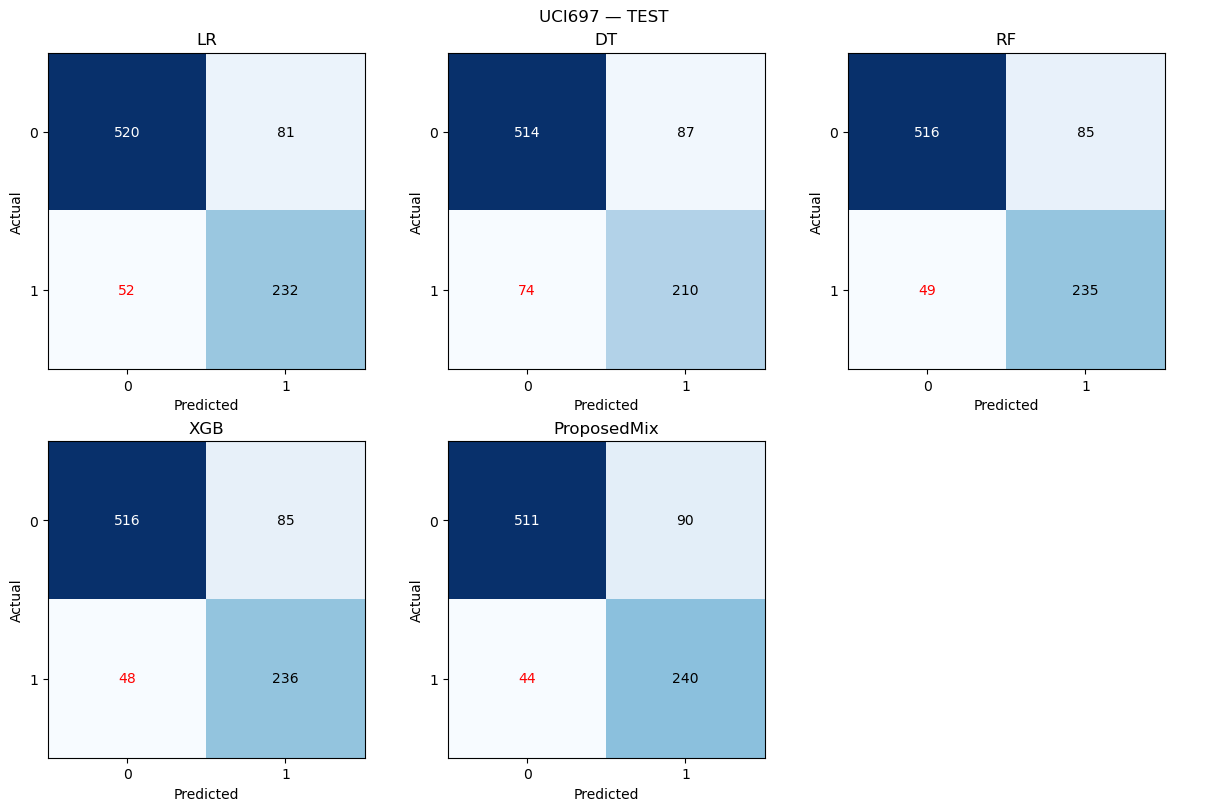

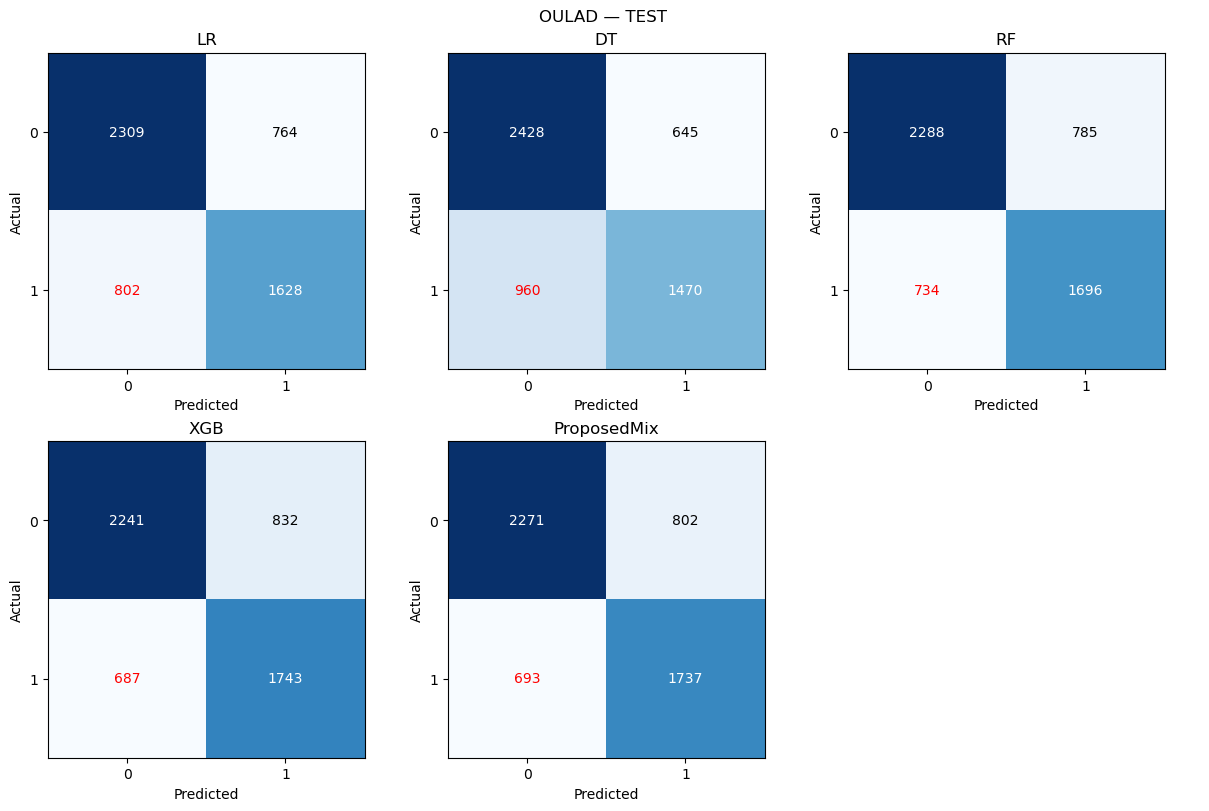

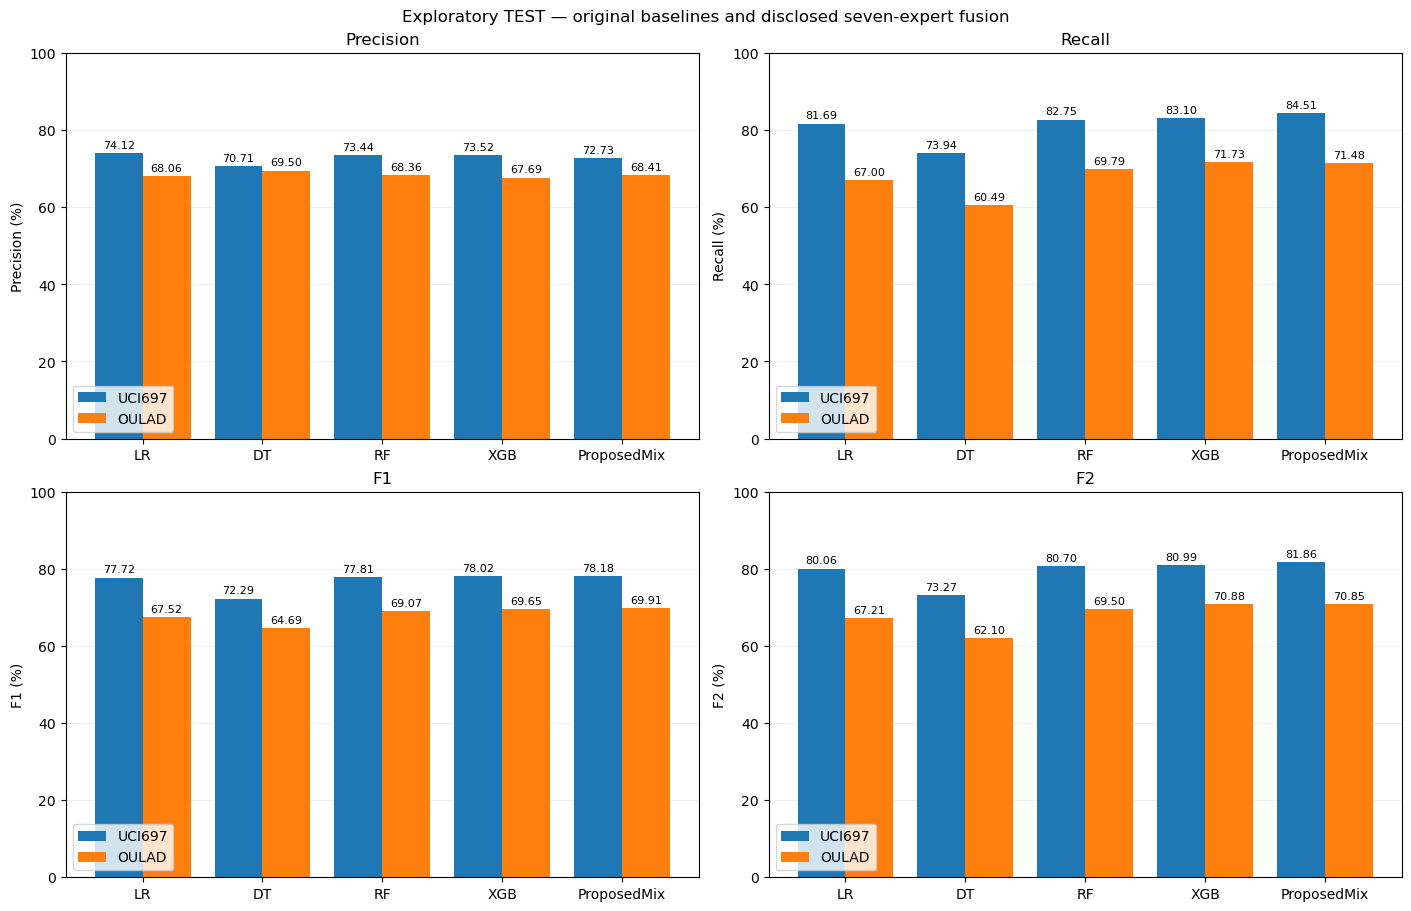

Target met: False


In [7]:
def plot_fusion_results(results, out):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    if not results:
        raise ValueError('No completed datasets to plot.')
    order = ['LR', 'DT', 'RF', 'XGB', 'ProposedMix']
    metrics = ['Precision', 'Recall', 'F1', 'F2']
    tables = []
    for dataset, source in results.items():
        table = source.copy()
        if table.Model.duplicated().any():
            raise ValueError(f'{dataset}: duplicate model rows.')
        table['Dataset'] = dataset
        indexed = table.set_index('Model')
        if not set(order).issubset(indexed.index):
            raise ValueError(f'{dataset}: missing one of the five main models.')
        tables.append(table)
        folder = out/dataset
        folder.mkdir(parents=True, exist_ok=True)
        fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout='constrained')
        for ax, name in zip(axes.flat, order):
            row = indexed.loc[name]
            matrix = np.array([[row.TN, row.FP], [row.FN, row.TP]], dtype=int)
            ax.imshow(matrix, cmap='Blues')
            for (r, c), count in np.ndenumerate(matrix):
                color = 'red' if (r, c)==(1, 0) else ('white' if count>matrix.max()/2 else 'black')
                ax.text(c, r, str(count), ha='center', va='center', color=color)
            ax.set(title=name, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1])
        axes.flat[-1].axis('off')
        fig.suptitle(dataset+' — TEST')
        fig.savefig(folder/'confusion_matrices.png', dpi=160)
        plt.show()
        plt.close(fig)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout='constrained')
    width = .8/len(results)
    for ax, metric in zip(axes.flat, metrics):
        for j, (dataset, table) in enumerate(results.items()):
            values = table.set_index('Model').loc[order, metric].to_numpy()*100
            bars = ax.bar(np.arange(5)+(j-(len(results)-1)/2)*width, values, width, label=dataset)
            ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=8)
        ax.set(title=metric, ylabel=metric+' (%)', ylim=(0, 100), xticks=np.arange(5), xticklabels=order)
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
        ax.legend(loc='lower left')
    fig.suptitle('Exploratory TEST — original baselines and disclosed seven-expert fusion')
    fig.savefig(out/'comparison.png', dpi=180)
    plt.show()
    plt.close(fig)
    combined = pd.concat(tables, ignore_index=True)
    combined.to_csv(out/'all_metrics.csv', index=False)
    return combined

results,joint_report=run_fusion(DATASETS,OUTPUT)
plot_fusion_results(results,OUTPUT)
(OUTPUT/"versions.json").write_text(json.dumps({n:version(n) for n in ["numpy","pandas","scipy","scikit-learn","xgboost","catboost","matplotlib"]},indent=2))
print("Target met:",joint_report["success"])


## Cell 8 — Lưu ZIP

Không train lại. Có trọng số7 và tổng theo5 họ, biểu đồ4 chỉ số/ma trận nhầm lẫn, bốn kết quả so người dẫn đầu, dự đoán, ablation, bootstrap, kiểm tra xác suất và giải thích TP/FP/FN/TN. ReplaceStateWithSignals và ReplaceAddedWithNative thay bằng chuyên gia nguồn sau hiệu chỉnh đúng nguồn; đây là đối chứng thay chuyên gia, không phải suy luận nhân quả. Ctrl+S để lưu riêng notebook có output.

In [ ]:
def _fusion_status(delta):
    return 'tie' if abs(float(delta)) <= 1e-9 else ('win' if delta > 0 else 'loss')

def _fusion_verify_decisions(table, predictions, dataset):
    if 'actual_risk' not in predictions:
        raise ValueError(f'{dataset}: predictions lack actual_risk.')
    y = predictions.actual_risk.to_numpy()
    if not np.isin(y, [0, 1]).all():
        raise ValueError(f'{dataset}: actual_risk must be binary.')
    for row in table.itertuples():
        column = row.Model+'_prediction'
        if column not in predictions:
            raise ValueError(f'{dataset}: missing decisions for {row.Model}.')
        a = predictions[column].to_numpy()
        if not np.isin(a, [0, 1]).all():
            raise ValueError(f'{dataset}: nonbinary decisions for {row.Model}.')
        a = a.astype(bool)
        tp, fp = int(((y==1)&a).sum()), int(((y==0)&a).sum())
        fn, tn = int(((y==1)&~a).sum()), int(((y==0)&~a).sum())
        values = dict(TP=tp, FP=fp, FN=fn, TN=tn, Precision=tp/max(tp+fp, 1),
                      Recall=tp/max(tp+fn, 1), F1=2*tp/max(2*tp+fp+fn, 1),
                      F2=5*tp/max(5*tp+fp+4*fn, 1))
        for key, expected in values.items():
            if hasattr(row, key) and not np.isclose(getattr(row, key), expected, atol=1e-10, rtol=0):
                raise ValueError(f'{dataset}/{row.Model}: {key} differs from saved decisions.')

def export_fusion_results(out, datasets):
    """Export real metrics and coefficients; reject altered configs or mismatched checks."""
    out = Path(out).resolve()
    datasets = list(datasets)
    if len(datasets)!=len(set(datasets)):
        raise ValueError('Dataset names must be unique.')
    baseline_names = ['LR', 'DT', 'RF', 'XGB']
    expected_experts = baseline_names+['CBNative', 'CBSignals', 'CBState']
    required = ['selection_before_test.json', 'checks.json', 'test_metrics.csv', 'test_predictions.csv']
    completed = [d for d in datasets if all((out/d/f).exists() for f in required)]
    if not completed:
        raise RuntimeError('Chưa có đầy đủ kết quả và quyết định test để xuất.')
    joint_file = out/'joint_selection_before_test.json'
    joint_hash = hashlib.sha256(joint_file.read_bytes()).hexdigest()
    joint_report_file = out/'joint_test_report.json'
    joint_report = json.loads(joint_report_file.read_text(encoding='utf-8'))
    if joint_report.get('joint_selection_sha256') != joint_hash:
        raise ValueError('Joint test report does not match the frozen joint selection.')
    tables, expert_rows, family_rows, criterion_rows, summaries = [], [], [], [], {}
    for dataset in completed:
        folder = out/dataset
        file = folder/'selection_before_test.json'
        config = json.loads(file.read_text(encoding='utf-8'))
        checks = json.loads((folder/'checks.json').read_text(encoding='utf-8'))
        if config['dataset'] != dataset:
            raise ValueError(f'{dataset}: wrong dataset name in frozen config.')
        actual_hash = hashlib.sha256(file.read_bytes()).hexdigest()
        if checks.get('selection_sha256') != actual_hash:
            raise ValueError(f'{dataset}: altered frozen config.')
        if config.get('joint_selection_sha256') != joint_hash or checks.get('joint_selection_sha256') != joint_hash:
            raise ValueError(f'{dataset}: joint selection checksum mismatch.')
        selected = config['selected_candidate']
        names, weights = list(selected['expert_names']), np.asarray(selected['weights'], dtype=float)
        if (len(names)!=7 or len(set(names))!=7 or set(names)!=set(expected_experts)
                or weights.shape!=(7,) or not np.isfinite(weights).all() or (weights<0).any()
                or not np.isclose(weights.sum(), 1., atol=1e-10, rtol=0)):
            raise ValueError(f'{dataset}: seven global nonnegative coefficients must sum to one.')
        weight_map = dict(zip(names, weights.tolist()))
        if set(checks['expert_weights'])!=set(names) or any(
                not np.isclose(checks['expert_weights'][n], weight_map[n], atol=1e-10, rtol=0) for n in names):
            raise ValueError(f'{dataset}: expert weight checks differ from frozen weights.')
        family = {n: weight_map[n] for n in baseline_names}
        family['CatBoost'] = sum(weight_map[n] for n in ['CBNative', 'CBSignals', 'CBState'])
        if set(checks['family_weights'])!=set(family) or any(
                not np.isclose(checks['family_weights'][n], family[n], atol=1e-10, rtol=0) for n in family):
            raise ValueError(f'{dataset}: five-family aggregate differs from expert weights.')
        feature_labels = dict(LR='Original baseline features', DT='Original baseline features',
                              RF='Original baseline features', XGB='Original baseline features',
                              CBNative='Native categorical handling; original features',
                              CBSignals='Native handling + early signals',
                              CBState='Native handling + early signals + state summaries')
        for name in names:
            expert_rows.append(dict(Dataset=dataset, Expert=name, Family='CatBoost' if name.startswith('CB') else name,
                                    Weight=weight_map[name], Features=feature_labels[name],
                                    Calibrated=bool(selected['calibrated'])))
        family_rows.append(dict(Dataset=dataset, **family, Sum=float(sum(family.values()))))
        table = pd.read_csv(folder/'test_metrics.csv', float_precision='round_trip')
        predictions = pd.read_csv(folder/'test_predictions.csv')
        if table.empty or predictions.empty or table.Model.duplicated().any():
            raise ValueError(f'{dataset}: empty or duplicate test results.')
        _fusion_verify_decisions(table, predictions, dataset)
        indexed = table.set_index('Model')
        if not set(baseline_names+['ProposedMix']).issubset(indexed.index):
            raise ValueError(f'{dataset}: missing a main model.')
        table['Dataset'] = dataset
        tables.append(table)
        deltas = {}
        for metric in ['Precision', 'Recall']:
            best = float(indexed.loc[baseline_names, metric].max())
            proposed = float(indexed.loc['ProposedMix', metric])
            leaders = indexed.loc[baseline_names].index[np.isclose(
                indexed.loc[baseline_names, metric], best, atol=1e-12, rtol=0)].tolist()
            delta = (proposed-best)*100
            deltas[metric] = delta
            if not np.isclose(checks['envelope_deltas'][metric], delta, atol=1e-9, rtol=0):
                raise ValueError(f'{dataset}: {metric} check is not versus the actual four-baseline maximum.')
            recorded = checks['test_leaders'][metric]
            if (not np.isclose(recorded['value'], best, atol=1e-12, rtol=0)
                    or set(recorded['models'])!=set(leaders)):
                raise ValueError(f'{dataset}: wrong {metric} baseline leaders.')
            if 'statuses' in checks and checks['statuses'][metric] != _fusion_status(delta):
                raise ValueError(f'{dataset}: raw {metric} status was misclassified.')
            criterion_rows.append(dict(Dataset=dataset, Metric=metric, Leaders=', '.join(leaders),
                                       Baseline_best_percent=best*100, Proposed_percent=proposed*100,
                                       Delta_pp=delta, Status=_fusion_status(delta),
                                       Practical_equivalence_0p1pp=abs(delta)<=.1+1e-9,
                                       Loss_within_1pp=delta>=-1.-1e-9,
                                       Absolute_change_within_1pp=abs(delta)<=1.+1e-9))
        comparisons = []
        mix = indexed.loc['ProposedMix']
        for name in indexed.index:
            if name.startswith(('CalSingle_CB', 'RawSingle_CB')) or name in {
                    'BaselineOnlyMix', 'ReplaceStateWithSignals', 'ReplaceAddedWithNative'}:
                row = indexed.loc[name]
                comparisons.append(dict(Control=name, Precision_delta_pp=float((mix.Precision-row.Precision)*100),
                                        Recall_delta_pp=float((mix.Recall-row.Recall)*100)))
        dominant_singles = [c['Control'] for c in comparisons if c['Control'].startswith(('CalSingle_CB','RawSingle_CB'))
                            and c['Precision_delta_pp']<=1e-9 and c['Recall_delta_pp']<=1e-9]
        explanation = [f'{dataset}: mô hình dùng 7 chuyên gia, thuộc 5 họ thuật toán; 3 biến thể CatBoost được công khai.',
                       'Trọng số được học, không âm, tổng bằng 1. Trọng số không phải bằng chứng nhân quả về đóng góp.',
                       'Các thay thế score giữ nguyên cấu hình/ngưỡng; đây là can thiệp chẩn đoán, không phải huấn luyện lại.']
        explanation += [f"{c['Control']}: mix trừ đối chứng: Precision {c['Precision_delta_pp']:+.6f} điểm %, Recall {c['Recall_delta_pp']:+.6f} điểm %."
                        for c in comparisons]
        if dominant_singles:
            explanation.append('Một chuyên gia bổ sung đã đạt hoặc vượt cả P/R của mix: '+', '.join(dominant_singles)
                               +'. Không thể quy toàn bộ cải thiện cho phép trộn.')
        else:
            explanation.append('Đối chứng chuyên gia bổ sung không đồng thời vượt P/R của mix ở các ngưỡng đã đóng băng; điều này chưa chứng minh đóng góp ổn định.')
        explanation.append('Kết quả thăm dò trên test đã xem nhiều lần; không chỉnh cấu hình theo kết quả này.')
        (folder/'fusion_interpretation.txt').write_text('\n'.join(explanation), encoding='utf-8')
        summaries[dataset] = dict(primary=config.get('primary'), calibrated=bool(selected['calibrated']),
                                  expert_weights=weight_map, family_weights=family, envelope_deltas=deltas,
                                  controls=comparisons, single_experts_matching_or_dominating=dominant_singles,
                                  selection_sha256=actual_hash)
    if len(completed)==len(datasets):
        by_label = {f'{r["Dataset"]}.{r["Metric"]}':r['Delta_pp'] for r in criterion_rows}
        order = joint_report.get('metric_order', [f'{d}.{m}' for d in sorted(completed) for m in ['Precision','Recall']])
        if set(order)!=set(by_label) or len(order)!=len(by_label):
            raise ValueError('Joint report criterion order does not match completed datasets.')
        if len(joint_report.get('deltas_pp', []))!=len(order) or not np.allclose(
                joint_report['deltas_pp'], [by_label[k] for k in order], atol=1e-9, rtol=0):
            raise ValueError('Joint report deltas differ from actual test metrics.')
    combined = pd.concat(tables, ignore_index=True)
    combined.to_csv(out/'all_metrics.csv', index=False)
    shown = combined[['Dataset', 'Model', 'Precision', 'Recall', 'F1', 'F2']].copy()
    shown[['Precision', 'Recall', 'F1', 'F2']] *= 100
    shown.to_csv(out/'metrics_percent.csv', index=False)
    expert_table = pd.DataFrame(expert_rows)
    expert_table.to_csv(out/'expert_weights_summary.csv', index=False)
    pd.DataFrame(family_rows).to_csv(out/'family_weights_summary.csv', index=False)
    pd.DataFrame(criterion_rows).to_csv(out/'four_criterion_comparison.csv', index=False)
    summary = dict(requested=datasets, completed=completed, missing=[d for d in datasets if d not in completed],
                   complete=len(completed)==len(datasets), results=summaries, joint_report=joint_report,
                   joint_selection_sha256=joint_hash, raw_equality_tolerance_pp=1e-9,
                   practical_equivalence_tolerance_pp=.1,
                   note='Raw metrics are never rounded or clipped to claim wins. Exploratory historical test.')
    (out/'export_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    archive_base = out.parent/('KET_QUA_'+out.name)
    if Path(str(archive_base)+'.zip').exists():
        archive_base = out.parent/('KET_QUA_'+out.name+'_'+uuid.uuid4().hex[:8])
    archive = Path(shutil.make_archive(str(archive_base), 'zip', root_dir=out))
    return shown, expert_table, archive

metrics_percent,expert_weights,ZIP_PATH=export_fusion_results(OUTPUT,DATASETS)
from IPython.display import display,FileLink
display(expert_weights.round(6))
display(metrics_percent.round(2))
display(pd.read_csv(OUTPUT/"four_criterion_comparison.csv"))
print("ZIP:",ZIP_PATH.resolve())
display(FileLink(os.path.relpath(ZIP_PATH,Path.cwd())))
